# Tải thư viện

In [1]:
%pip install -U  transformers datasets peft accelerate huggingface_hub safetensors  torch torchvision torchaudio torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 62.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 63.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.0/248.0 MB 4.2 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found exis

In [ ]:
# # 1. Clean out the potentially corrupted packages
# !pip uninstall torch torchvision torchaudio transformers accelerate -y

# # 2. Clear out pip's cached wheels to avoid re-installing a broken package
# !pip cache purge

# # 3. Install fresh, compatible versions
# !pip install torch torchvision --index-url https://pytorch.org
# !pip install -U accelerate "transformers[torch]"

# Mount drive (nếu ở colab)

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Import lib

In [4]:
import os
import json, torch
import pandas as pd
import json
import os
from pathlib import Path
from dotenv import load_dotenv

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM,
    TrainingArguments, Trainer, DataCollatorForSeq2Seq
)
from peft import LoraConfig, get_peft_model


# Load env nếu ở local
load_dotenv()

# Device
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

W1013 02:54:41.477000 561 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1013 02:54:41.637000 561 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Device: cuda


# Config & Path

In [38]:
# Thông tin từ HuggingFace
BASE_MODEL = "ntphuc149/ViLegalQwen2.5-1.5B-Base"
HF_MODEL_REPO = "tmtdev/ViLegalQwen2.5-CitationInference-V1"
HF_DATASET_REPO = "tmtdev/ViLegal-QRHE-Dataset"

# task
TASK_ID = "LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION"

# Cấu hình model
MAX_LENGTH = 1024

# Cấu hình đương dẫn dữ liệu
ROOT_DIR = Path("/content")
# DATA_DIR = ROOT_DIR / "content/drive/MyDrive/legal-ai/data"  # COLAB
# # DATA_DIR = ROOT_DIR / "../data/retrieval/"  # LOCAL
# DATA_PATH = os.path.join(DATA_DIR, "LegalQRHE_all.csv")
# OUTPUT_DIR = ROOT_DIR / ".." / "drive/MyDrive/legal-ai/models/v1"

# Lưu ý: Thư mục trên Google Drive là "My Drive" (có dấu cách)
DATA_DIR = Path('/content/drive/My Drive/legal-ai/data')

# Đường dẫn file CSV
DATA_PATH = DATA_DIR / 'LegalQRHE_all.json'

# Thư mục lưu model
OUTPUT_DIR = Path('/content/drive/My Drive/legal-ai/models/v1')

print("Root directory:", ROOT_DIR.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Data path:", DATA_PATH)
print("Output directory:", OUTPUT_DIR.resolve())

if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    print(f"Created output directory: {OUTPUT_DIR}")

# Cấu hình chế độ
IS_PUSH_DATASET_TO_HF = True

# HF_TOKEN
HF_TOKEN = os.getenv("HF_TOKEN")
print("HF_TOKEN:", "Available" if HF_TOKEN else "Not Available")

# Các cột cần có trong dữ liệu
REQUIRED_COLUMNS = ["input",  "output", "task_id"]

Root directory: /content
Data directory: /content/drive/My Drive/legal-ai/data
Data path: /content/drive/My Drive/legal-ai/data/LegalQRHE_all.json
Output directory: /content/drive/My Drive/legal-ai/models/v1
HF_TOKEN: Not Available


# Tải data từ file ở Drive đã upload lên

In [40]:
def load_json_file(file_path: str) -> list[dict]:
        """
        Load JSON data from a file.
        """
        if not Path(file_path).exists():
            print(f"File not found: {file_path}")
            raise FileNotFoundError(f"File not found: {file_path}")

        with open(file_path, 'r', encoding='utf-8') as f:
            data = json.load(f)
        return data

def load_csv_file(file_path: str) -> list[dict]:
        """
        Load CSV data from a file and convert it to a list of dictionaries.
        """
        if not Path(file_path).exists():
            print(f"File not found: {file_path}")
            raise FileNotFoundError(f"File not found: {file_path}")

        df = pd.read_csv(file_path)
        return df.to_dict(orient='records')

def eda_data(data: list[dict]):
    df = pd.DataFrame(data=data)

    display(df.head())
    display(df.info())


def split(legal_data: list[dict], test_size: float = 0.2):
    print("Cấu trúc 1 dòng mẫu:", legal_data[0])

    print("Các cột cần thiết:", REQUIRED_COLUMNS)
    print("Số dòng dữ liệu ban đầu:", len(legal_data))
    data = Dataset.from_list(legal_data).filter(
        lambda x: all(x.get(k) for k in REQUIRED_COLUMNS)
    )
    print("Số dòng sau khi lọc:", len(data))

    splits = data.train_test_split(test_size=test_size, seed=42)
    temp = splits["test"].train_test_split(test_size=0.5, seed=42)

    train_data = splits["train"]
    val_data = temp["train"]
    test_data = temp["test"]

    print(len(train_data), len(val_data), len(test_data))

    return train_data, val_data, test_data


# Enable push
if IS_PUSH_DATASET_TO_HF:
    # Load
    # if DATA_PATH.endswith(".json"):
    # elif DATA_PATH.endswith(".csv"):
    #     legal_data: list[dict] = load_csv_file(DATA_PATH)
    # else:
    #     raise ValueError("Unsupported file format. Please provide a .json or .csv file.")
    legal_data: list[dict] = load_json_file(DATA_PATH)

    print("Số dòng dữ liệu:", len(legal_data))

    # EDA
    eda_data(legal_data)

    # Split
    train_data, val_data, test_data = split(legal_data)
else:
    print("NOT PUSH DATASET")


Số dòng dữ liệu: 10548


,task_id,input,output
0,LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION,Chương I của Hiến pháp nước Cộng hòa xã hội ch...,"{'part': None, 'chapter': 'I', 'section': None..."
1,LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION,Nội dung Điều 1 theo Hiến pháp nước Cộng hòa x...,"{'part': None, 'chapter': None, 'section': Non..."
2,LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION,Điều 1 thuộc Chương I theo Hiến pháp nước Cộn...,"{'part': None, 'chapter': 'I', 'section': None..."
3,LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION,Điều 2 của Hiến pháp nước Cộng hòa xã hội chủ ...,"{'part': None, 'chapter': None, 'section': Non..."
4,LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION,Điều 2 thuộc Chương I theo Hiến pháp nước Cộn...,"{'part': None, 'chapter': 'I', 'section': None..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10548 entries, 0 to 10547
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   task_id  10548 non-null  object
 1   input    10548 non-null  object
 2   output   10548 non-null  object
dtypes: object(3)
memory usage: 247.3+ KB


None

Cấu trúc 1 dòng mẫu: {'task_id': 'LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION', 'input': 'Chương I của Hiến pháp nước Cộng hòa xã hội chủ nghĩa Việt Nam năm 2013 quy định về vấn đề gì?', 'output': {'part': None, 'chapter': 'I', 'section': None, 'subsection': None, 'article': None, 'clause': None, 'point': None, 'document': 'Hiến pháp nước Cộng hòa xã hội chủ nghĩa Việt Nam năm 2013'}}
Các cột cần thiết: ['input', 'output', 'task_id']
Số dòng dữ liệu ban đầu: 10548


Filter:   0%|          | 0/10548 [00:00<?, ? examples/s]

Số dòng sau khi lọc: 10548
8438 1055 1055


# Push data lên Huggingface

In [41]:
from huggingface_hub import login, create_repo, HfApi
from huggingface_hub import notebook_login
from datasets import DatasetDict
import os

# bật để disable XET (eXperimental Tokenizer) in Hugging Face Hub, which can help avoid potential issues with tokenization when pushing datasets or models to the hub.
os.environ["HF_HUB_DISABLE_XET"] = "1"

# Or use 'huggingface-cli login' in the terminal
notebook_login()
login()

api = HfApi()
whoami_info = api.whoami()
print("Tài khoản HuggingFace:", whoami_info.get("fullname", ""))

if IS_PUSH_DATASET_TO_HF:
  dataset = DatasetDict({
      "train": train_data,
      "validation": val_data,
      "test": test_data
  })

  # Push dataset
  dataset.push_to_hub(
      repo_id=HF_DATASET_REPO,
      private=False
  )

  print(f"Dataset pushed to HuggingFace Hub at: https://huggingface.co/datasets/{HF_DATASET_REPO}")
else:
  print("NOT PUSH DATASET")



Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Tài khoản HuggingFace: Minh Thuyên Trần


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpaogreih5.parquet    : 100%|##########| 47.6kB / 47.6kB            

Validating                    :           |   0%            

Dataset pushed to HuggingFace Hub at: https://huggingface.co/datasets/tmtdev/ViLegal-QRHE-Dataset


# Tải data từ huggingface (Nếu ở đã push lên Huggingface trước đó)

In [42]:
from datasets import load_dataset

dataset = load_dataset(HF_DATASET_REPO)
print(dataset)
train_data = dataset["train"]
val_data = dataset["validation"]
test_data = dataset["test"]

README.md:   0%|          | 0.00/871 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 47.6kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8438 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1055 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1055 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['task_id', 'input', 'output'],
        num_rows: 8438
    })
    validation: Dataset({
        features: ['task_id', 'input', 'output'],
        num_rows: 1055
    })
    test: Dataset({
        features: ['task_id', 'input', 'output'],
        num_rows: 1055
    })
})


# Kiểm tra data

Data Columns: ['task_id', 'input', 'output']


,dataset,size
0,train,8438
1,validation,1055
2,test,1055


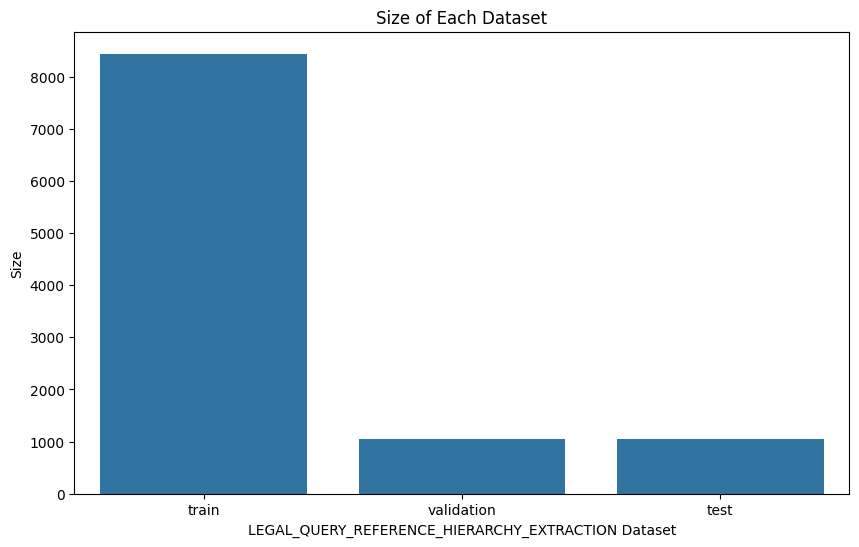

In [43]:
if len(train_data) == 0 or len(val_data) == 0 or len(test_data) == 0:
    raise ValueError("One of the datasets (train, validation, test) is empty. Please check the dataset.")

print("Data Columns:", train_data.column_names)

# check columns
for col in REQUIRED_COLUMNS:
    if col not in train_data.column_names:
        raise ValueError(f"Column {col} is missing in the training data.")
    if col not in val_data.column_names:
        raise ValueError(f"Column {col} is missing in the validation data.")
    if col not in test_data.column_names:
        raise ValueError(f"Column {col} is missing in the test data.")


df_eda = pd.DataFrame(
    [{
        "dataset": "train",
        "size": len(train_data)
    }, {
        "dataset": "validation",
        "size": len(val_data)
    }, {
        "dataset": "test",
        "size": len(test_data)
    }]
)

display(df_eda)


# Vẽ hình size các tập
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(data=df_eda, x="dataset", y="size")
plt.title("Size of Each Dataset")
plt.xlabel(TASK_ID + " Dataset")
plt.ylabel("Size")
plt.show()

# Huấn luyện mô hình

- Sử dụng message template
- Role: system, user, assistant

## Khởi tạo tokenizer

In [9]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
tokenizer.pad_token = tokenizer.pad_token or tokenizer.eos_token
tokenizer.padding_side = "right"


config.json:   0%|          | 0.00/708 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.26k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

## Hướng dẫn prompt cho mô hình

In [11]:
class Prompt:
    SYSTEM_PROMPT = """
    Bạn là model AI xử lý các nhiệm vụ pháp luật Việt Nam.
    Thực hiện đúng TASK được chỉ định trong đầu vào.
    Tuân thủ schema đầu ra của task đó.
    Không tự bịa thông tin hoặc căn cứ pháp luật.
    """

    # TASK: LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION
    LEGAL_QRHE_PROMPT = """
    TASK: LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION

    Nhiệm vụ:
    Trích xuất các cấp trích dẫn và văn bản pháp luật
    được đề cập rõ ràng trong query_text.

    Chỉ trả về JSON hợp lệ gồm các trường:
    document, part, chapter, section, subsection,
    article, clause, point.

    Cấp không được đề cập phải là null.
    Giá trị trích dẫn là chuỗi.
    Không suy đoán, bịa đặt hoặc bổ sung thông tin.
    Tuân thủ đúng schema đầu ra.
    """


## Tạo message template (khuôn mẫu hội thọi)

In [44]:
def validate_output(
    output: dict,
    required_keys: list = ["document", "part", "chapter", "section", "subsection", "article", "clause", "point"]
) -> bool:
    if not isinstance(output, dict):
        print("Output is not a dictionary.")
        return False
    res = all(key in output for key in required_keys)
    if not res:
        print(f"Output is missing required keys.",
              "\nRequired keys:", required_keys,
              "\nOutput keys:", list(output.keys()))
    return res

def build_messages(task_id: str, input: str):

    allowed_task_ids = ["LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION"]
    if task_id not in allowed_task_ids:
        raise ValueError(f"Unknown task_id: {task_id}. Allowed task_ids: {allowed_task_ids}")

    if task_id == "LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION":
        return [
            {
                "role": "system",
                "content": Prompt.SYSTEM_PROMPT},
            {
                "role": "user",
                "content": (
                    f"{Prompt.LEGAL_QRHE_PROMPT}\n\n"
                    f"query_text: {input}"
                )
            }
        ]

    return [
        {
            "role": "system",
            "content": Prompt.SYSTEM_PROMPT},
        {
            "role": "user",
            "content": (
                f"{Prompt.LEGAL_QRHE_PROMPT}\n\n"
                f"query_text: {input}"
            )
        }
    ]

def preprocess(
    example: dict,
    return_dict: bool=True
):
    '''
    Hướng dẫn prompt cho mô hình
    Encode nội dung
    Trả về dict với input_ids, attention_mask, labels
    '''

    task_id = example["task_id"]
    input = example["input"]
    output = json.dumps(example["output"], ensure_ascii=False)

    prompt = build_messages(task_id=task_id, input=input)

    full = prompt + [{"role": "assistant", "content": output}]

    prompt_result = tokenizer.apply_chat_template(
        prompt,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=return_dict
    )

    full_result = tokenizer.apply_chat_template(
        full,
        tokenize=True,
        add_generation_prompt=False,
        return_dict=return_dict
    )

    prompt_ids = prompt_result["input_ids"]
    full_ids = full_result["input_ids"]

    # Một số trường hợp trả về dict/BatchEncoding
    if isinstance(prompt_ids, dict):
        prompt_ids = prompt_ids["input_ids"]

    if isinstance(full_ids, dict):
        full_ids = full_ids["input_ids"]

    prompt_ids = list(prompt_ids)
    full_ids = list(full_ids)

    full_ids = full_ids[:MAX_LENGTH]
    prompt_len = min(len(prompt_ids), len(full_ids))


    """
    • Trong thư viện PyTorch, hàm tính toán độ lỗi phổ biến là CrossEntropyLoss cấu hình mặc định tham số ignore_index = -100.
    Khi hàm này thấy nhãn có giá trị là -100, nó sẽ bỏ qua tự động và không tính điểm lỗi cho token đó.
    1. [-100] * prompt_len: Tạo ra một danh sách chứa toàn các số -100, với độ dài bằng đúng số lượng từ/token của phần câu lệnh (prompt_len).
    Điều này đảm bảo toàn bộ phần câu lệnh sẽ không bị tính loss.
    2. +: Ghép nối hai danh sách lại với nhau.
    3. full_ids[prompt_len:]: Lấy các ID token thực tế của phần câu trả lời (phần còn lại sau câu lệnh).
    Đây là phần mà mô hình bắt buộc phải học để dự đoán chính xác, nên giữ nguyên ID gốc của từ thay vì thay bằng -100.
    """
    labels = [-100] * prompt_len + full_ids[prompt_len:]

    return {
        "input_ids": full_ids,
        "attention_mask": [1] * len(full_ids),
        "labels": labels
    }


# map dữ liệu sang định dạng input_ids, attention_mask, labels
train_data_encoded = train_data.map(
    preprocess,
    remove_columns=train_data.column_names,
    fn_kwargs={"return_dict": True}
)

val_data_encoded = val_data.map(
    preprocess,
    remove_columns=val_data.column_names,
    fn_kwargs={"return_dict": True}
)

test_data_encoded = test_data.map(
    preprocess,
    remove_columns=test_data.column_names,
    fn_kwargs={"return_dict": True}
)

Map:   0%|          | 0/8438 [00:00<?, ? examples/s]

Map:   0%|          | 0/1055 [00:00<?, ? examples/s]

Map:   0%|          | 0/1055 [00:00<?, ? examples/s]

In [45]:
sample = preprocess(train_data[0])

print("Token types:", set(type(x).__name__ for x in sample["input_ids"]))
print("Input length:", len(sample["input_ids"]))
print("Label length:", len(sample["labels"]))

label_ids = [
    token_id
    for token_id in sample["labels"]
    if token_id != -100
]

print(tokenizer.decode(label_ids))

Token types: {'int'}
Input length: 271
Label length: 271
{"part": null, "chapter": null, "section": null, "subsection": null, "article": "355", "clause": "2", "point": null, "document": "Bộ luật Dân sự 2015"}<|im_end|>



## Kiểm tra message template

In [46]:
result = tokenizer.apply_chat_template(
    [{"role": "user", "content": "test"}],
    tokenize=True,
    add_generation_prompt=True
)

print(type(result))
print(result.keys() if hasattr(result, "keys") else type(result))

<class 'transformers.tokenization_utils_base.BatchEncoding'>
KeysView({'input_ids': [151644, 8948, 198, 2610, 525, 264, 10950, 17847, 13, 151645, 198, 151644, 872, 198, 1944, 151645, 198, 151644, 77091, 198], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]})


In [47]:
# Kiểm tra dữ liệu đã encode
print(train_data_encoded.column_names)
print(train_data_encoded)
print(type(train_data_encoded[0]["input_ids"]))
print(train_data_encoded[0]["input_ids"][:5])

['input_ids', 'attention_mask', 'labels']
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 8438
})
<class 'list'>
[151644, 8948, 271, 262, 129096]


## Cấu hình và Khởi tạo model

In [48]:


model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32, # Deprecated warning
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

model.config.use_cache = False
model.gradient_checkpointing_enable()

lora = {
    "r": 16,
    "lora_alpha": 32,
    "lora_dropout": 0.05
}

model = get_peft_model(model, LoraConfig(
    r=lora["r"],
    lora_alpha=lora["lora_alpha"],
    lora_dropout=lora["lora_dropout"],
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
    task_type="CAUSAL_LM"
))


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [49]:
model.print_trainable_parameters()

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


## Chạy huấn luyên mô hình

In [50]:
args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=1,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    fp16=torch.cuda.is_available(),
    logging_steps=20,
    save_total_limit=2,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_data_encoded,
    eval_dataset=val_data_encoded,
    data_collator=DataCollatorForSeq2Seq(
        tokenizer=tokenizer,
        label_pad_token_id=-100
    )
)

trainer.train()

Epoch,Training Loss,Validation Loss
1,0.129175,0.129786


TrainOutput(global_step=528, training_loss=0.13353705473921515, metrics={'train_runtime': 2686.7427, 'train_samples_per_second': 3.141, 'train_steps_per_second': 0.197, 'total_flos': 1.9543293447868416e+16, 'train_loss': 0.13353705473921515, 'epoch': 1.0})

## Các điểm đánh giá và lưu mô hình

In [51]:
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print(f"Model saved to: {OUTPUT_DIR}")

Model saved to: /content/drive/My Drive/legal-ai/models/v1


In [52]:
# Validation và test loss
val_metrics = trainer.evaluate(
    eval_dataset=val_data_encoded,
    metric_key_prefix="val"
)

test_metrics = trainer.evaluate(
    eval_dataset=test_data_encoded,
    metric_key_prefix="test"
)

print("Validation:", val_metrics)
print("Test:", test_metrics)

Training Loss,Validation Loss,Epoch
0.129175,0.129786,1


Training Loss,Validation Loss,Epoch
0.129175,0.129662,1


Validation: {'val_loss': 0.12978637218475342}
Test: {'test_loss': 0.1296623945236206}


## Lưu model lên Huggingface

In [53]:
from huggingface_hub import login
login()

model.push_to_hub(HF_MODEL_REPO, private=False)
tokenizer.push_to_hub(HF_MODEL_REPO, private=False)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 45.7kB / 73.9MB            

Validating                    :           |   0%            

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpevripb2u/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/tmtdev/ViLegalQwen2.5-CitationInference-V1/commit/85b85e93d810a544fb5b8354845fdcb70ec5174a', commit_message='Upload tokenizer', commit_description='', oid='85b85e93d810a544fb5b8354845fdcb70ec5174a', pr_url=None, repo_url=RepoUrl('https://huggingface.co/tmtdev/ViLegalQwen2.5-CitationInference-V1', endpoint='https://huggingface.co', repo_type='model', repo_id='tmtdev/ViLegalQwen2.5-CitationInference-V1'), pr_revision=None, pr_num=None)

# Dự đoán mô hình

In [54]:
import json
import torch

import re

def parse_json_output(text):
    """Lấy object JSON đầu tiên trong output của model."""
    text = text.strip()

    # Loại bỏ Markdown code fence nếu có
    text = re.sub(r"^```(?:json)?\s*", "", text)
    text = re.sub(r"\s*```$", "", text)

    decoder = json.JSONDecoder()
    start = text.find("{")

    if start == -1:
        return None

    try:
        obj, _ = decoder.raw_decode(text[start:])
        return obj if isinstance(obj, dict) else None
    except json.JSONDecodeError:
        return None

def predict(
    input_text: str,
    return_dict: bool,
    task_id: str = "LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION",
    max_new_tokens: int = 256,
):
    messages = build_messages(task_id=task_id, input=input_text)

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=return_dict
    ).to(model.device)

    # Qwen dùng <|im_end|> để kết thúc một lượt hội thoại
    im_end_id = tokenizer.convert_tokens_to_ids("<|im_end|>")

    stop_ids = [tokenizer.eos_token_id]
    if im_end_id is not None and im_end_id not in stop_ids:
        stop_ids.append(im_end_id)

    model.eval()

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            eos_token_id=stop_ids,
            pad_token_id=tokenizer.pad_token_id
                if tokenizer.pad_token_id is not None
                else tokenizer.eos_token_id,
            repetition_penalty=1.05,
        )

    input_length = inputs["input_ids"].shape[-1]

    raw_output = tokenizer.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    ).strip()

    # Nếu model sinh thêm nội dung sau JSON, chỉ lấy object JSON đầu tiên
    try:
        decoder = json.JSONDecoder()
        start = raw_output.find("{")

        if start == -1:
            print("Không tìm thấy '{' trong output. Trả về raw_output.")
            return {
                "output": None,
                "raw_output": raw_output,
            }

        parsed, _ = decoder.raw_decode(raw_output[start:])
        return {
            "output": parsed,
            "raw_output": raw_output,
        }

    except json.JSONDecodeError:
        print("JSONDecodeError: Không thể parse output thành JSON. Trả về raw_output.")
        return {
            "output": None,
            "raw_output": raw_output,
        }



In [34]:
sample = train_data_encoded[0]

print("INPUT:")
print(tokenizer.decode(sample["input_ids"]))

print("\nLABEL TOKENS:")
label_ids = [
    token_id
    for token_id in sample["labels"]
    if token_id != -100
]
print(tokenizer.decode(label_ids))

INPUT:
<|im_start|>system

    Bạn là model AI xử lý các nhiệm vụ pháp luật Việt Nam.
    Thực hiện đúng TASK được chỉ định trong đầu vào.
    Tuân thủ schema đầu ra của task đó.
    Không tự bịa thông tin hoặc căn cứ pháp luật.
    <|im_end|>
<|im_start|>user

    TASK: LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION

    Nhiệm vụ:
    Trích xuất các cấp trích dẫn và văn bản pháp luật
    được đề cập rõ ràng trong query_text.

    Chỉ trả về JSON hợp lệ gồm các trường:
    document, part, chapter, section, subsection,
    article, clause, point.

    Cấp không được đề cập phải là null.
    Giá trị trích dẫn là chuỗi.
    Không suy đoán, bịa đặt hoặc bổ sung thông tin.
    Tuân thủ đúng schema đầu ra.
    

query_text: Nội dung Khoản 2 Điều 355 theo Bộ luật Dân sự 2015 là gì?<|im_end|>
<|im_start|>assistant
"{'part': None, 'chapter': None, 'section': None, 'subsection': None, 'article': '355', 'clause': '2', 'point': None, 'document': 'Bộ luật Dân sự 2015'}"<|im_end|>


LABEL TOKENS:
"{'par

In [55]:
test_input = "Theo khoản 2 Điều 13 Nghị định 10/2020/NĐ-CP, thời gian lưu trữ hình ảnh là bao lâu?"
result = predict(
    test_input,
    max_new_tokens=256,
    return_dict=True
)

print(f"Input: {test_input}")
print(f"Output: {json.dumps(result, ensure_ascii=False, indent=2)}")



Input: Theo khoản 2 Điều 13 Nghị định 10/2020/NĐ-CP, thời gian lưu trữ hình ảnh là bao lâu?
Output: {
  "output": {
    "part": null,
    "chapter": null,
    "section": null,
    "subsection": null,
    "article": "13",
    "clause": "2",
    "point": null,
    "document": "Nghị định 10/2020/NĐ-CP"
  },
  "raw_output": "{\"part\": null, \"chapter\": null, \"section\": null, \"subsection\": null, \"article\": \"13\", \"clause\": \"2\", \"point\": null, \"document\": \"Nghị định 10/2020/NĐ-CP\"}��取\n(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt)(egt"
}
Nhậ

# Chạy đánh giá mô hình

## Load model từ Huggingface

## Load lại test data từ Huggingface

In [56]:
from datasets import load_dataset

raw_test = load_dataset(HF_DATASET_REPO, split="test")

print("Số lượng mẫu test:", len(raw_test))
print("Ví dụ mẫu test:", raw_test[0])

Số lượng mẫu test: 1055
Ví dụ mẫu test: {'task_id': 'LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION', 'input': 'Nội dung Khoản 1 Điều 157 theo Bộ luật Dân sự 2015 là gì?', 'output': {'part': None, 'chapter': None, 'section': None, 'subsection': None, 'article': '157', 'clause': '1', 'point': None, 'document': 'Bộ luật Dân sự 2015'}}


## Lưu kết quả đánh giá

In [61]:
import time

start = time.perf_counter()

res = predict(
    input_text=test[0]["input"],
    task_id=test[0]["task_id"],
    return_dict=True,
    max_new_tokens=128
)

elapsed = time.perf_counter() - start

print(f"Thời gian/mẫu: {elapsed:.2f}s")
print("Raw output:", res.get("raw_output"))

Thời gian/mẫu: 26.42s
Raw output: {"part": null, "chapter": null, "section": null, "subsection": null, "article": "157", "clause": "1", "point": null, "document": "Bộ luật Dân sự 2015"}��取
�始化assistant
{"part": null, "chapter": null, "section": null, "subsection": null, "article": "157", "clause": "1", "point": null, "document": "Bộ luật Dân sự 2015"}Cumhurba
(egt)TRGL
VRTX
(egt)TRGL
VRTX


In [62]:
import time
import torch

messages = build_messages(
    task_id="LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION",
    input="Nội dung Khoản 1 Điều 157 theo Bộ luật Dân sự 2015 là gì?"
)

start = time.perf_counter()

inputs = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt",
    return_dict=True,
).to(model.device)

if torch.cuda.is_available():
    torch.cuda.synchronize()

t1 = time.perf_counter()

model.eval()
with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=128,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=[
            tokenizer.eos_token_id,
            tokenizer.convert_tokens_to_ids("<|im_end|>"),
        ],
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

t2 = time.perf_counter()

input_len = inputs["input_ids"].shape[1]
new_tokens = outputs.shape[1] - input_len

print(f"Tokenize: {t1 - start:.2f}s")
print(f"Generate: {t2 - t1:.2f}s")
print(f"Generated tokens: {new_tokens}")
print(f"Generation speed: {new_tokens / max(t2 - t1, 1e-9):.2f} tokens/s")

Tokenize: 0.04s
Generate: 23.30s
Generated tokens: 128
Generation speed: 5.49 tokens/s


In [63]:
import time
import torch

for max_tokens in [32, 64, 128]:
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            eos_token_id=[
                tokenizer.eos_token_id,
                tokenizer.convert_tokens_to_ids("<|im_end|>"),
            ],
            pad_token_id=tokenizer.pad_token_id,
            use_cache=True,
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    generated = outputs.shape[1] - inputs["input_ids"].shape[1]

    print(
        f"max_tokens={max_tokens}, "
        f"actual_tokens={generated}, "
        f"time={elapsed:.2f}s"
    )

max_tokens=32, actual_tokens=32, time=9.47s
max_tokens=64, actual_tokens=64, time=17.79s
max_tokens=128, actual_tokens=128, time=12.73s


In [60]:
# Các tiêu chi đánh giá: đúng cấu trúc JSON,
# Đầy đủ: document, part, chapter, section, subsection, article, clause, point



# Chạy đánh giá
results = []
test = raw_test.to_list()  # Giới hạn số mấu test
print(test[0])
for i, example in enumerate(test):
    if (i + 1) % 10 == 0:
        print(f"Đang đánh giá mẫu {i+1}/{len(raw_test)}...")

    input = example['input']
    task_id = example['task_id']

    res = predict(
        input_text=input,
        task_id=task_id,
        return_dict=True,
        max_new_tokens=256
    )
    pred = res.get("output")
    raw_output = res.get("raw_output")

    expected_output = example["output"]

    valid_json = pred is not None

    correct_keys = (
        valid_json
        and set(pred.keys()) == {
            "document", "part", "chapter", "section", "subsection",
            "article", "clause", "point"
        }
    )

    output_ok = (
        correct_keys
        and isinstance(pred, type(expected_output))
    )

    results.append({
        "input": input,
        "expected_output": json.dumps(expected_output, ensure_ascii=False),
        "predicted_output": json.dumps(pred, ensure_ascii=False) if valid_json else None,
        "valid_json": valid_json,
        "correct_keys": correct_keys,
        "output_format_ok": output_ok,
        "output_exact_match": (
            pred == expected_output
            if correct_keys else False
        ),
        "raw_output": raw_output
    })


df = pd.DataFrame(results)

# Tổng hợp các metric
metrics = [
    "valid_json",
    "correct_keys",
    "output_format_ok",
    "output_exact_match",
]

summary = pd.DataFrame({
    "metric": metrics,
    "score_percent": [
        100 * df[m].mean() for m in metrics
    ]
})

print(summary.to_string(index=False))

# Xem những mẫu model dự đoán sai
errors = df[~df["output_exact_match"]]

display(errors.head(10))



# Lưu kết quả để phân tích
from datetime import datetime
task_id = "LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION"
time = datetime.now().strftime("%Y%m%d_%H%M%S")
df.to_csv(
    os.path.join(OUTPUT_DIR, f"test_evaluation_{task_id}_{time}.csv"),
    index=False,
    encoding="utf-8-sig"
)

{'task_id': 'LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION', 'input': 'Nội dung Khoản 1 Điều 157 theo Bộ luật Dân sự 2015 là gì?', 'output': {'part': None, 'chapter': None, 'section': None, 'subsection': None, 'article': '157', 'clause': '1', 'point': None, 'document': 'Bộ luật Dân sự 2015'}}


KeyboardInterrupt: 

## Lưu kết quả đánh giá tập Test

In [ ]:

# Lưu kết quả để phân tích
task_id = "LEGAL_QUERY_REFERENCE_HIERARCHY_EXTRACTION"
from datetime import datetime
time = datetime.now().strftime("%Y%m%d_%H%M%S")
df.to_csv(
    os.path.join(OUTPUT_DIR, f"test_evaluation_{task_id}_{time}.csv"),
    index=False,
    encoding="utf-8-sig"
)